# Forward Euler step by step, the threshold and the final-size oracle

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- compute one Forward Euler step by hand and see it equal the engine's;
- read $R_0 = \beta / \gamma$ as the threshold between a fading and a growing outbreak;
- solve the final-size relation and use it as an oracle that does not depend on the time course;
- measure that the engine's error shrinks at first order in the step.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and prints their versions.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


As in notebook 01, the engine is imported from `data-pipeline/` by its path.

In [2]:
# The notebook sits three folders below the repository root; the pipeline's modules are imported by their path
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams
from pipeline.oracles import final_size

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Data

The same five baked cases as notebook 01.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json`.

The next cell defines the two readers again and lists the cases.

In [3]:
# Two readers of the committed artifacts: a missing file stops the notebook and names its path
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("cases that can take off:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
cases that can take off: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


This cell reads the parameters of every case and prints $R_0$ next to them. The parameters are all this notebook needs from the data.

In [4]:
# List the parameters of every case with its basic reproduction ratio R0 = beta / gamma
for case_id in CASES:
    p = params_of(case_id)
    print(f"{case_id:18s} beta={p.beta:.2f} gamma={p.gamma:.2f} N={p.N:.0f} I0={p.I0:.0f} R0={p.beta / p.gamma:.2f}")

CTRL_degenerate    beta=0.40 gamma=0.20 N=100000 I0=0 R0=2.00
EX01_subcritical   beta=0.18 gamma=0.25 N=100000 I0=50 R0=0.72
EX02_epidemic      beta=0.55 gamma=0.20 N=100000 I0=50 R0=2.75
EX03_fast_burn     beta=1.20 gamma=0.20 N=100000 I0=100 R0=6.00
EX04_slow_spread   beta=0.30 gamma=0.25 N=100000 I0=50 R0=1.20


## Method

### 1. One Forward Euler step, by hand

Forward Euler advances the state by the rates at its start, times the step $\Delta t$ (Hairer, Norsett and Wanner, 1993). For the SIR system, with $S_k, I_k, R_k$ the state after $k$ steps:

$$\Delta_{inf} = \beta \frac{S_k I_k}{N} \Delta t, \quad \Delta_{rec} = \gamma I_k \Delta t, \quad S_{k+1} = S_k - \Delta_{inf}, \quad I_{k+1} = I_k + \Delta_{inf} - \Delta_{rec}, \quad R_{k+1} = R_k + \Delta_{rec}$$

This cell computes the first step of the epidemic case by hand, only to read what the engine does, and compares it with the first step of the engine's own run. The whole run stays with `simulate`: the notebook does not re-implement it.

In [5]:
# One step by hand from the initial state, then the engine's first step for comparison
p = params_of("EX02_epidemic")
dt = 0.25
S0, I0, R_start = p.N - p.I0, p.I0, 0.0
new_infections = p.beta / p.N * S0 * I0 * dt
new_recoveries = p.gamma * I0 * dt
by_hand = (S0 - new_infections, I0 + new_infections - new_recoveries, R_start + new_recoveries)

run = simulate(p)
engine = (run.S[1], run.I[1], run.R[1])
print("new infections:", round(new_infections, 4), "| new recoveries:", round(new_recoveries, 4))
print("by hand:", [round(v, 4) for v in by_hand])
print("engine: ", [round(v, 4) for v in engine])
print("equal:", bool(np.allclose(by_hand, engine)))

new infections: 6.8716 | new recoveries: 2.5
by hand: [99943.1284, 54.3716, 2.5]
engine:  [99943.1284, 54.3716, 2.5]
equal: True


### 2. The threshold R0 = beta / gamma

$R_0$ is the basic reproduction ratio: the average number of people one infected person infects in a fully susceptible population (Diekmann, Heesterbeek and Metz, 1990). For compartmental models, $R_0 < 1$ is the stability condition of the disease-free state (van den Driessche and Watmough, 2002): an outbreak fades. This cell runs every case with the engine and sets the peak of infected people against the initial infected, next to $R_0$.

In [6]:
# Run every case and compare the peak of infected people with the initial infected people
for case_id in CASES:
    p = params_of(case_id)
    r = simulate(p)
    r0 = p.beta / p.gamma
    grows = r.peak_I > p.I0 * 1.000001
    print(f"{case_id:18s} R0={r0:4.2f}  I0={p.I0:5.0f}  peak={r.peak_I:9.1f} on day {r.t_peak:6.2f}  grows={grows}")

CTRL_degenerate    R0=2.00  I0=    0  peak=      0.0 on day   0.00  grows=False
EX01_subcritical   R0=0.72  I0=   50  peak=     50.0 on day   0.00  grows=False
EX02_epidemic      R0=2.75  I0=   50  peak=  27345.2 on day  24.25  grows=True
EX03_fast_burn     R0=6.00  I0=  100  peak=  55265.1 on day   9.25  grows=True
EX04_slow_spread   R0=1.20  I0=   50  peak=   1520.8 on day  96.25  grows=True


### 3. The final size as an oracle

Whatever the time course, the fraction $z$ of the population that is ever infected solves the final-size relation (Kermack and McKendrick, 1927; Miller, 2012):

$$z = 1 - e^{-R_0 z}$$

For $R_0 \le 1$ the only solution is $z = 0$. This cell solves it with `final_size` of `data-pipeline/pipeline/oracles.py` (a fixed-point iteration, an oracle that shares no code with the engine) and compares it with the attack rate the engine reports. The relation holds for a run that ends inside its horizon, so the cell also prints the share of the population still infected at the horizon.

In [7]:
# Solve z = 1 - exp(-R0 z) by fixed-point iteration and compare with the engine's attack rate
print(f"{'case':18s} {'R0':>5s} {'z':>8s} {'engine':>8s} {'diff':>8s} {'still infected':>15s}")
for case_id in CASES:
    p = params_of(case_id)
    r = simulate(p)
    z = final_size(p.beta / p.gamma)
    print(f"{case_id:18s} {p.beta / p.gamma:5.2f} {z:8.4f} {r.attack_rate:8.4f} {r.attack_rate - z:8.4f} {r.I[-1] / p.N:15.6f}")

case                  R0        z   engine     diff  still infected
CTRL_degenerate     2.00   0.7968   0.0000  -0.7968        0.000000
EX01_subcritical    0.72   0.0000   0.0018   0.0018        0.000000
EX02_epidemic       2.75   0.9204   0.9237   0.0032        0.000000
EX03_fast_burn      6.00   0.9975   0.9982   0.0007        0.000000
EX04_slow_spread    1.20   0.3137   0.2993  -0.0144        0.002890


### 4. First-order convergence in the step

The global error of Forward Euler is first order in the step (Hairer, Norsett and Wanner, 1993): halving $\Delta t$ halves the error. Without an exact solution at hand, this cell runs the engine with steps 1, 1/2, 1/4, 1/8 and 1/16 of a day, takes the differences between consecutive results, and estimates the observed order as $\log_2$ of the ratio of consecutive differences. An order near 1 is first order.

dt= 1.0000  attack rate=0.933717
dt= 0.5000  attack rate=0.926912
dt= 0.2500  attack rate=0.923654
dt= 0.1250  attack rate=0.922060
dt= 0.0625  attack rate=0.921271
differences between consecutive steps: ['0.006805', '0.003258', '0.001595', '0.000789']
observed order: [1.06, 1.03, 1.02]


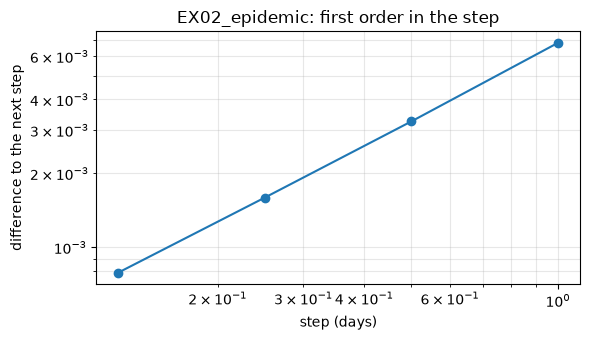

In [8]:
# Run the engine at five steps, difference the attack rates and estimate the observed order
p = params_of("EX02_epidemic")
steps = [1.0, 0.5, 0.25, 0.125, 0.0625]
attack = [simulate(p, dt=h).attack_rate for h in steps]
diffs = np.abs(np.diff(attack))
orders = np.log2(diffs[:-1] / diffs[1:])

for h, a in zip(steps, attack):
    print(f"dt={h:7.4f}  attack rate={a:.6f}")
print("differences between consecutive steps:", [f"{d:.6f}" for d in diffs])
print("observed order:", [round(float(o), 2) for o in orders])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(steps[:-1], diffs, "o-")
ax.set_xlabel("step (days)")
ax.set_ylabel("difference to the next step")
ax.set_title("EX02_epidemic: first order in the step")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## Results

What the cells show, in order:

1. The step computed by hand equals the engine's first step: the engine is the update rule above, nothing more.
2. The sub-critical case (R0 below 1) never rises above its initial infected people; every case with R0 above 1 grows to a peak. The control, with no initial infection, has nothing to grow, whatever its R0.
3. For the epidemic and the fast-burn cases the final-size relation agrees with the engine's attack rate within a few thousandths, and the engine's value is the larger: Forward Euler at a quarter-day step overshoots a little. The slow-spread case still has people infected at the horizon (the last column), so the relation does not apply to it and its attack rate is below $z$; this is the limit of the oracle, not an engine error. The control, with no initial infection, has nothing to spread, so the non-trivial solution of the relation does not apply to it (its table row shows the engine at zero). The relation here is the one for a vanishing initial infection; the next topic refines it.
4. The differences between consecutive steps halve each time the step halves, and the observed orders are close to 1: the engine converges at first order, as the method predicts. The figure shows the differences falling on a line of slope 1 in logarithmic axes.

## Summary

- Forward Euler is one update rule applied 640 times; the engine implements exactly that.
- $R_0 = \beta / \gamma$ separates the cases that fade from those that take off.
- The final-size relation is an oracle independent of the time course, valid for a run that ends inside its horizon.
- The engine's error falls at first order in the step.
- Next: topic 02 uses the threshold and the final size on their own, and compares them with the state of the art.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Diekmann, O., Heesterbeek, J. A. P. and Metz, J. A. J. (1990). On the definition and the computation of the basic reproduction ratio R0 in models for infectious diseases in heterogeneous populations. Journal of Mathematical Biology. https://doi.org/10.1007/BF00178324
- van den Driessche, P. and Watmough, J. (2002). Reproduction numbers and sub-threshold endemic equilibria for compartmental models of disease transmission. Mathematical Biosciences. https://doi.org/10.1016/S0025-5564(02)00108-6
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the cases of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

What each work is credited with is what the research basis of the SDD (`docs/design/SDD.md`) records; the text of their pages was not re-read, only their Crossref records.